# Module project: diagnosis with uncertainty, by MCMC

This notebook builds the whole project, file by file, exactly as the lesson does. Run it from top to bottom in Google Colab or Jupyter: each `%%writefile` cell writes one file of the project, and each `!python` cell runs it. Then try the ideas under **Make it yours**.

Better still: type the files yourself in your own editor, and use this notebook to check your work.

## Attachments and data

- **Notebook**: `project-3-bayesian-logreg-mcmc.ipynb`, attached to this lesson. It builds and runs the whole project; on the course's web page it opens in Google Colab.
- **Finished code**: the `projects/bayesian-logreg-mcmc` folder in the course files, to check your work.
- **Data**: No download: the breast cancer data set ships with scikit-learn (`load_breast_cancer`; UCI, CC BY 4.0).

In [ ]:
%pip install -q torch scikit-learn matplotlib

Every model so far in this course has chosen **one** set of weights. Bayesian thinking says that's overconfident: many
weight vectors explain the data almost equally well, and an honest prediction should average over all of them. The
posterior distribution `p(w | data)` has no closed form for logistic regression, but chapter 14 gives you a way to draw
samples from it anyway: **Markov chain Monte Carlo**.

In this project you write two samplers, a random walk (section 14.2.1) and Langevin sampling with gradients (section
14.3), run them on a real medical data set, measure honestly how well they work, and use the samples to say which
patients the model is unsure about. The notebook attached above builds and runs the whole project; the reference code
is in the course files under `projects/bayesian-logreg-mcmc`.

## What you'll build

```mermaid
flowchart LR
    A[breast cancer data<br/>569 patients, 30 measurements] --> B[model.py<br/>log posterior,<br/>its gradient, MAP]
    B --> C[samplers.py<br/>Metropolis<br/>Langevin MALA]
    C --> D[run.py<br/>effective sample size,<br/>predictions with<br/>uncertainty]
```

## Set up the project

```bash
mkdir bayesian-logreg-mcmc && cd bayesian-logreg-mcmc
python -m venv .venv && source .venv/bin/activate
pip install torch scikit-learn matplotlib
git init
```

```text
bayesian-logreg-mcmc/
    .gitignore
    README.md
    model.py
    requirements.txt
    run.py
    samplers.py
```

In [ ]:
%%writefile requirements.txt
torch
scikit-learn
matplotlib

Writing requirements.txt


In [ ]:
%%writefile .gitignore
outputs/
__pycache__/
.venv/

Writing .gitignore


## Step 1: the posterior

The model is part 1's logistic regression: `p(benign | x) = σ(wᵀx)`, with a bias and 30 standardized measurements, so 31
weights. A Gaussian prior with standard deviation 1 on each weight, times the Bernoulli likelihood of the 400 training
patients, gives the posterior up to a constant. That's all MCMC needs: we never have to normalize it.

`grad_log_posterior` uses autograd for the gradient the Langevin sampler needs, and `find_map` finds the single most
probable weight vector with L-BFGS. Starting the chains there saves a long "burn-in".

In [ ]:
%%writefile model.py
"""Bayesian logistic regression on the breast cancer data: the posterior over weights we want to sample from."""
import torch
from sklearn.datasets import load_breast_cancer

d = load_breast_cancer()
X = torch.tensor(d.data, dtype=torch.float64)
t = torch.tensor(d.target, dtype=torch.float64)                  # 1 = benign, 0 = malignant
order = torch.randperm(len(X), generator=torch.Generator().manual_seed(0))
train, test = order[:400], order[400:]
mean, std = X[train].mean(0), X[train].std(0)
X = torch.cat([torch.ones(len(X), 1, dtype=torch.float64), (X - mean) / std], 1)   # bias column + 30 features
D = X.shape[1]
PRIOR_STD = 1.0


def log_posterior(w):
    """log p(w | data) up to a constant: Bernoulli log likelihood of the training set + Gaussian prior."""
    a = X[train] @ w
    log_lik = (t[train] * a - torch.nn.functional.softplus(a)).sum()
    return log_lik - 0.5 * (w ** 2).sum() / PRIOR_STD ** 2


def grad_log_posterior(w):
    w = w.detach().requires_grad_(True)
    log_posterior(w).backward()                                   # autograd gives the gradient for Langevin
    return w.grad


def find_map():
    """The most probable weights (MAP), by L-BFGS: a good place to start the chains."""
    w = torch.zeros(D, dtype=torch.float64, requires_grad=True)
    opt = torch.optim.LBFGS([w], max_iter=200, line_search_fn="strong_wolfe")

    def closure():
        opt.zero_grad(); loss = -log_posterior(w); loss.backward(); return loss
    opt.step(closure)
    return w.detach()

Writing model.py


Everything is in float64: log-probabilities of 400 patients add up to large numbers, and small differences between them
decide every accept-or-reject.

## Step 2: two samplers

**Random-walk Metropolis** (section 14.2.1): propose a random jump from the current weights; if the posterior is higher
there, go; if lower, go with probability `p(new) / p(old)`. Simple, and it only needs the posterior's value.

**Langevin** (section 14.3): instead of jumping blindly, take a step **uphill** along the gradient of `log p`, plus noise.
On its own that gives samples that are slightly off; adding a Metropolis-Hastings acceptance step (with the proposal's
own density, `log_q`) makes them exact. This combination is called MALA.

In [ ]:
%%writefile samplers.py
"""Two MCMC samplers (Bishop, sections 14.2.1 and 14.3)."""
import torch
from model import log_posterior, grad_log_posterior


def metropolis(w0, steps, step_size, seed=0):
    """Random-walk Metropolis: propose a random jump, accept it with probability min(1, p(new)/p(old))."""
    g = torch.Generator().manual_seed(seed)
    w, lp, samples, accepted = w0.clone(), log_posterior(w0), [], 0
    for _ in range(steps):
        proposal = w + step_size * torch.randn(w.shape, generator=g, dtype=w.dtype)
        lp_new = log_posterior(proposal)
        if torch.rand(1, generator=g, dtype=w.dtype).log() < lp_new - lp:
            w, lp, accepted = proposal, lp_new, accepted + 1
        samples.append(w.clone())
    return torch.stack(samples), accepted / steps


def mala(w0, steps, step_size, seed=0):
    """Langevin: move along the gradient of log p, plus noise (section 14.3), then a Metropolis-Hastings
    correction so the samples are exact (the 'Metropolis-adjusted Langevin algorithm')."""
    g = torch.Generator().manual_seed(seed)
    eps = step_size

    def log_q(to, frm, grad_frm):                                   # proposal density q(to | frm)
        return -((to - frm - 0.5 * eps ** 2 * grad_frm) ** 2).sum() / (2 * eps ** 2)

    w, lp, grad = w0.clone(), log_posterior(w0), grad_log_posterior(w0)
    samples, accepted = [], 0
    for _ in range(steps):
        proposal = w + 0.5 * eps ** 2 * grad + eps * torch.randn(w.shape, generator=g, dtype=w.dtype)
        lp_new, grad_new = log_posterior(proposal), grad_log_posterior(proposal)
        log_ratio = lp_new - lp + log_q(w, proposal, grad_new) - log_q(proposal, w, grad)
        if torch.rand(1, generator=g, dtype=w.dtype).log() < log_ratio:
            w, lp, grad, accepted = proposal, lp_new, grad_new, accepted + 1
        samples.append(w.clone())
    return torch.stack(samples), accepted / steps

Writing samplers.py


Step sizes matter. Too small and the chain crawls; too large and almost every proposal is rejected. We tuned them to
acceptance rates near the usual targets: about 0.23 for random-walk Metropolis, about 0.57 for MALA.

## Step 3: run, diagnose, predict

A chain's samples are correlated: each one is close to the previous. The **effective sample size** says how many
independent samples a chain is worth, from its autocorrelation. It's the honest measure of what a sampler achieved.

In [ ]:
%%writefile run.py
"""Sample the posterior with both samplers, compare how well they explore, then use the samples to predict
with honest uncertainty."""
from pathlib import Path
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from model import X, t, test, find_map
from samplers import metropolis, mala

STEPS, BURN = 5000, 1000


def effective_sample_size(x):
    """How many independent samples a correlated chain is worth (sum of autocorrelations until they turn negative)."""
    x = x - x.mean()
    n, var = len(x), (x * x).mean()
    rho_sum = 0.0
    for lag in range(1, n // 2):
        rho = (x[:-lag] * x[lag:]).mean() / var
        if rho < 0:
            break
        rho_sum += rho
    return n / (1 + 2 * rho_sum)


w_map = find_map()
chains = {"random-walk Metropolis": metropolis(w_map, STEPS, 0.2), "Langevin (MALA)": mala(w_map, STEPS, 0.2)}
print(f"{'sampler':24s} {'acceptance':>10s} {'effective samples (worst / median weight)':>42s}")
for name, (samples, acc) in chains.items():
    ess = torch.tensor([effective_sample_size(samples[BURN:, j]) for j in range(samples.shape[1])])
    print(f"{name:24s} {acc:10.2f} {ess.min():22.0f} / {ess.median():.0f}   (of {STEPS - BURN} kept)")

# Prediction: average the probability over posterior samples, instead of trusting one weight vector
samples = chains["Langevin (MALA)"][0][BURN:]
p_samples = torch.sigmoid(X[test] @ samples.T)                     # (patients, samples)
p_bayes, p_spread = p_samples.mean(1), p_samples.std(1)
p_map = torch.sigmoid(X[test] @ w_map)
for name, p in [("MAP (one weight vector)", p_map), ("posterior average", p_bayes)]:
    ll = (t[test] * p.log() + (1 - t[test]) * (1 - p).log()).mean()
    print(f"\n{name:24s} test accuracy {((p > 0.5) == t[test].bool()).double().mean():.3f}, "
          f"test log likelihood per patient {ll:.3f}", end="")
print()

# Which patients is the model unsure about? The ones whose probability varies most across the posterior.
print("\nmost uncertain test patients:")
for i in p_spread.argsort(descending=True)[:4]:
    lo, hi = p_samples[i].quantile(0.05).item(), p_samples[i].quantile(0.95).item()
    print(f"  truth {'benign   ' if t[test][i] else 'malignant'} MAP says {p_map[i]:.2f}, posterior {p_bayes[i]:.2f} "
          f"(90% interval {lo:.2f} to {hi:.2f})")

Path("outputs").mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(8, 3))
for name, (s, _) in chains.items():
    ax.plot(s[:, 1], lw=0.7, label=name)
ax.set_xlabel("step"); ax.set_ylabel("weight of 'mean radius'"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig("outputs/traces.png", dpi=110)
print("\nsaved outputs/traces.png")

Writing run.py


In [ ]:
!python run.py

sampler                  acceptance  effective samples (worst / median weight)
random-walk Metropolis         0.21                      5 / 16   (of 4000 kept)
Langevin (MALA)                0.68                     15 / 39   (of 4000 kept)

MAP (one weight vector)  test accuracy 0.970, test log likelihood per patient -0.076
posterior average        test accuracy 0.964, test log likelihood per patient -0.062

most uncertain test patients:
  truth malignant MAP says 0.29, posterior 0.42 (90% interval 0.00 to 0.98)
  truth benign    MAP says 0.46, posterior 0.46 (90% interval 0.08 to 0.90)
  truth malignant MAP says 0.59, posterior 0.55 (90% interval 0.12 to 0.91)
  truth benign    MAP says 0.46, posterior 0.44 (90% interval 0.10 to 0.85)

saved outputs/traces.png


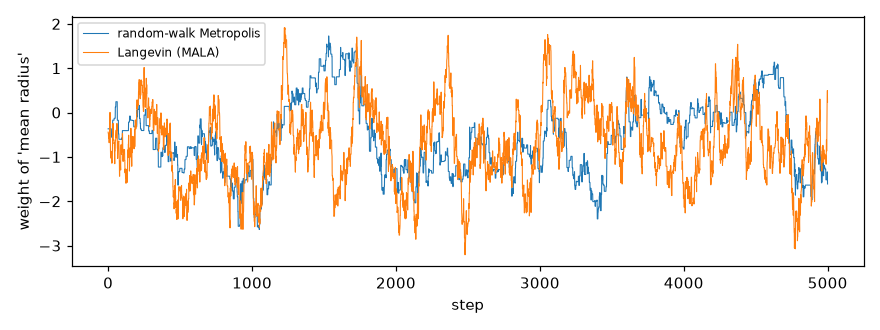

In [ ]:
from IPython.display import Image
Image('outputs/traces.png')

**The samplers.** Out of 4,000 samples, random-walk Metropolis is worth only 5 independent samples for its worst
weight, and 16 for the median one. Langevin does about three times better (15 and 39). The trace plot shows why: the
random walk wanders slowly, Langevin moves faster. But neither is good. The 30 measurements are strongly correlated (the
radius, perimeter and area of a cell nucleus nearly determine each other), so the posterior is a long, thin ridge in 31
dimensions, the hardest shape for MCMC. Reporting this is more valuable than hiding it. Chapter 14's more advanced
samplers, or removing redundant features, are the fix.

**The predictions.** Averaging the probability over the posterior samples barely changes the accuracy (0.970 vs 0.964,
one patient out of 169), but it improves the test log likelihood from −0.076 to −0.062: the probabilities are better.

**The uncertainty.** This is what a single weight vector can't give you. For the most uncertain patients, the posterior
says "somewhere between 0.00 and 0.98": the data simply doesn't decide. The MAP model would report 0.29 for the first of
them as if it knew. In medicine, "I don't know, run another test" is a valuable answer.

## Step 4: write the README and publish

In [ ]:
%%writefile README.md
# Bayesian logistic regression with MCMC

Samples the posterior over the 31 weights of a logistic regression for breast cancer diagnosis (569 patients,
scikit-learn), with two samplers written in PyTorch: random-walk Metropolis and the Metropolis-adjusted Langevin
algorithm, which uses autograd gradients. Then predicts with the whole posterior instead of a single weight vector.

![traces](outputs/traces.png)

## Results

| sampler | acceptance | effective samples, worst / median weight (of 4,000) |
|---|---|---|
| random-walk Metropolis | 0.21 | 5 / 16 |
| Langevin (MALA) | 0.68 | 15 / 39 |

| prediction (169 test patients) | accuracy | log likelihood per patient |
|---|---|---|
| MAP weights | 0.970 | -0.076 |
| posterior average | 0.964 | **-0.062** |

For the hardest patients the posterior gives 90% intervals as wide as 0.00 to 0.98: the model knows it doesn't know.

## Run it

```bash
pip install -r requirements.txt
python run.py      # about 2 minutes
```

## What I learned

- MCMC replaces "the best weights" with thousands of plausible weights, and predictions average over them.
- Gradients help: Langevin explored about 3 times faster than a random walk, but correlated features make this posterior
  hard for both. Effective sample size, not the number of steps, says how much you've learned.
- Averaging over the posterior improved the probabilities more than the accuracy.

Based on chapter 14 of *Deep Learning: Foundations and Concepts* (Bishop & Bishop, 2024).

Writing README.md


```bash
git add .
git commit -m "Bayesian logistic regression with Metropolis and Langevin MCMC"
git branch -M main
git remote add origin git@github.com:YOUR-USERNAME/bayesian-logreg-mcmc.git
git push -u origin main
```

## Make it yours

- **Fewer, less correlated features.** Keep only 5 measurements that aren't strongly correlated. How much does the
  effective sample size improve?
- **Hamiltonian Monte Carlo.** Take several gradient steps per proposal, with momentum ("leapfrog" steps). It's the
  sampler behind modern tools like Stan and PyMC. Does it beat MALA per gradient evaluation?
- **Several chains.** Run 4 chains from different starting points and compare them (the R-hat diagnostic). Do they agree?
- **A cost-aware decision.** Combine the posterior with a loss matrix (part 1, section 5.2) that makes missing a
  malignant tumour 20 times worse than a false alarm.

## On your CV

> **Bayesian diagnosis with MCMC** (PyTorch): Bayesian logistic regression on the breast cancer data set with
> random-walk Metropolis and gradient-based Langevin (MALA) samplers; measured effective sample size (MALA 3x better),
> and improved test log likelihood from -0.076 to -0.062 by averaging over the posterior, with per-patient uncertainty
> intervals. github.com/YOUR-USERNAME/bayesian-logreg-mcmc

## Check yourself

- [ ] You can explain the Metropolis accept rule, and why the normalizing constant isn't needed.
- [ ] You can explain why the effective sample size is much smaller than the number of steps.
- [ ] You can explain what the posterior gives you that the MAP weights don't.